# Mesin Pencari Cerpen Indonesia
### Perbandingan BM25 dan LM Dirichlet dengan Custom Preprocessing pada Elasticsearch

UAS Praktikum Penelusuran Informasi · Kategori: Cerpen / Cerita Fiksi

Notebook ini mendokumentasikan seluruh proses pembangunan sistem penelusuran cerpen, mulai dari pengumpulan korpus sampai evaluasi dan analisis hasil. Antarmuka pencarian berada di aplikasi terpisah (`app.py`) dan memakai indeks, modul preprocessing, serta kamus sinonim yang dihasilkan di sini.

**Daftar isi**

1. Pendahuluan
2. Setup environment dan konfigurasi
3. Crawling dan pengumpulan korpus
4. Penyaringan dokumen dan duplicate checking
5. Custom preprocessing
6. Konfigurasi Elasticsearch dan indexing
7. Model retrieval: BM25, LM Dirichlet, dan baseline
8. Query expansion dengan sinonim
9. Relevance feedback dengan algoritma Rocchio
10. Relevance judgment dan evaluasi sistem
11. Analisis hasil
12. Kesimpulan

## 1. Pendahuluan

### Latar belakang

Cerpen berbeda dari teks berita atau artikel informatif. Panjangnya beragam, bahasanya naratif dan banyak memuat dialog, dan kosakatanya sering bersifat sastrawi. Kebutuhan pencarian pun cenderung tematik ("ibu menunggu anak pulang", "perang dan pengungsian") dan jarang berupa fakta yang jawabannya tertulis eksplisit di satu kalimat. Kondisi ini membuat pilihan preprocessing dan model retrieval berpengaruh langsung pada kualitas hasil.

### Tujuan

Membangun mesin pencari untuk korpus cerpen berbahasa Indonesia yang dikumpulkan sendiri, lalu menjawab tiga pertanyaan:

1. Apakah preprocessing yang dirancang khusus untuk cerpen memperbaiki hasil dibandingkan analyzer standar?
2. Mana yang lebih sesuai untuk korpus ini: BM25 atau LM Dirichlet?
3. Bagaimana query expansion dengan sinonim dan relevance feedback (Rocchio) mengubah query dan peringkat hasil?

### Konfigurasi yang dibandingkan

| Konfigurasi | Teks yang diindeks | Analyzer pada indeks | Model |
|---|---|---|---|
| `cerpen_bm25` | token hasil preprocessing custom | `whitespace` | BM25 |
| `cerpen_lmd` | token hasil preprocessing custom | `whitespace` | LM Dirichlet |
| `cerpen_baseline` | teks mentah (judul + isi) | `standard` | BM25 |

Ketiganya memakai korpus dan query uji yang sama. Selisih antara `cerpen_baseline` dan `cerpen_bm25` mengisolasi pengaruh preprocessing (modelnya sama), sedangkan selisih `cerpen_bm25` dan `cerpen_lmd` membandingkan dua model dengan preprocessing yang sama.

### Alur sistem

```
Crawling (sitemap) -> Penyaringan + duplicate checking -> raw_corpus.json
        -> Custom preprocessing (preprocess.py) -> clean_corpus.json
        -> Elasticsearch: tiga indeks (BM25 / LM Dirichlet / baseline)
        -> Pencarian: query diproses dengan preprocess.py yang sama
              + query expansion (sinonim) + Rocchio
        -> Relevance judgment manual (pooling) -> metrik -> analisis
```

Elasticsearch dipakai sebagai pengganti PyLucene, yang termasuk alternatif resmi pada ketentuan tugas. Elasticsearch dibangun di atas Apache Lucene dan menyediakan model BM25 dan LM Dirichlet bawaan, term vector, dan API untuk membaca statistik indeks.

## 2. Setup environment dan konfigurasi

Notebook dikembangkan di Google Colab dan membutuhkan Elasticsearch 8.x yang dapat diakses di `localhost:9200`. Semua berkas hasil disimpan di satu folder kerja (`WORK_DIR`), yaitu folder Google Drive di Colab atau direktori aktif di lingkungan lain. Beberapa tahap memakai pola "muat jika sudah ada" agar korpus, korpus bersih, dan lembar penilaian tidak berubah antar eksekusi. Hal ini penting karena nomor dokumen pada penilaian relevansi mengacu pada urutan `raw_corpus.json`.

In [1]:
!pip -q install PySastrawi elasticsearch==8.11.0 scipy beautifulsoup4

In [2]:
import os, re, json, time, math, random, hashlib, collections, subprocess, sys, importlib
from collections import defaultdict
from pathlib import Path
from datetime import datetime, timezone

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# Folder kerja: Google Drive di Colab, direktori aktif di lingkungan lain
try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = "/content/drive/MyDrive/uas_pi_cerpen"
except ImportError:
    WORK_DIR = os.path.abspath(".")
os.makedirs(WORK_DIR, exist_ok=True)
sys.path.insert(0, WORK_DIR)

RAW_ALL      = f"{WORK_DIR}/raw_all.jsonl"          # hasil crawling mentah (semua halaman)
RAW_CORPUS   = f"{WORK_DIR}/raw_corpus.json"        # korpus mentah terpilih, unik
CLEAN_CORPUS = f"{WORK_DIR}/clean_corpus.json"      # korpus hasil preprocessing
DUP_REPORT   = f"{WORK_DIR}/duplicates_report.csv"  # bukti duplicate checking
SYN_FILE     = f"{WORK_DIR}/synonyms.json"          # kamus sinonim (juga dipakai app.py)
JUDGE_BLANK  = f"{WORK_DIR}/judgment_sheet.csv"     # lembar penilaian (pool, kolom nilai kosong)
JUDGE_FILLED = f"{WORK_DIR}/judgment_sheet_filled.csv"  # penilaian relevansi manual
POOL_INFO    = f"{WORK_DIR}/pool_info.json"         # asal tiap dokumen pool (metode, peringkat)
print("Folder kerja:", WORK_DIR)

Mounted at /content/drive
Folder kerja: /content/drive/MyDrive/uas_pi_cerpen


## 3. Crawling dan pengumpulan korpus

Korpus dikumpulkan sendiri dari dua blog cerpen berbasis WordPress. Daftar URL posting diambil dari `sitemap.xml` masing-masing situs, lalu tiap halaman diunduh dengan jeda 1 detik antar permintaan. `robots.txt` kedua situs tidak melarang halaman posting.

| Sumber | Karakter |
|---|---|
| `cerpenkompas.wordpress.com` | kumpulan cerpen koran, bergaya sastra |
| `kumpulanfiksi.wordpress.com` | campuran puisi, esai, cerita bersambung, dan cerpen |

Beberapa sumber lain dicoba tetapi tidak dipakai: `cerpenmu.com` tidak dapat diakses, `storial.co` ternyata memuat artikel menulis berbahasa Inggris dengan jumlah URL di bawah 500, dan halaman sebuah blog Blogspot yang diperiksa hanya berisi daftar judul (13 kata).

Judul diambil dari meta `og:title`, sedangkan isi diambil dari elemen dengan teks paragraf terbanyak setelah elemen non-konten (menu, komentar, tombol bagikan) dibuang. Cara ini tidak bergantung pada nama class tema WordPress tertentu.

In [4]:
from bs4 import BeautifulSoup

HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}
DELAY = 1.0
WP_POST = re.compile(r"^https?://[^/]+/\d{4}/\d{2}/\d{2}/[^/]+/?$")
SOURCES = [
    ("cerpenkompas", "https://cerpenkompas.wordpress.com", WP_POST),
    ("kumpulanfiksi", "https://kumpulanfiksi.wordpress.com", WP_POST),
]
NOISE = ["script", "style", "nav", "footer", "aside", "form", "noscript",
         ".sharedaddy", ".jp-relatedposts", "#comments", ".comments-area",
         ".wpcnt", "#jp-post-flair", ".post-share-buttons", ".post-footer"]

In [5]:
def http_get(url, tries=3):
    for i in range(tries):
        try:
            r = requests.get(url, timeout=30, headers=HEADERS)
            if r.status_code == 200:
                return r
            if r.status_code in (429, 503):
                time.sleep(5 * (i + 1))
        except Exception:
            time.sleep(3)
    return None

def sitemap_urls(url, depth=0):
    # sitemap WordPress berupa indeks yang menunjuk ke sitemap lain
    r = http_get(url)
    if r is None or depth > 2:
        return []
    out = []
    for loc in re.findall(r"<loc>(.*?)</loc>", r.text):
        out += sitemap_urls(loc, depth + 1) if loc.endswith(".xml") else [loc]
    return out

def extract_post(html):
    soup = BeautifulSoup(html, "html.parser")
    og = soup.find("meta", property="og:title")
    title = og["content"] if og and og.get("content") else (soup.title.get_text() if soup.title else "")
    title = re.split(r"\s[|–-]\s", title)[0].strip()
    cats = sorted({a.get_text(strip=True) for a in soup.select('a[rel~="category"], a[rel~="tag"]')})
    for sel in NOISE:
        for t in soup.select(sel):
            t.decompose()
    # kontainer isi = induk dengan total teks paragraf terbanyak
    scores = {}
    for p in soup.find_all("p"):
        par = p.parent
        scores.setdefault(id(par), [par, 0])
        scores[id(par)][1] += len(p.get_text(strip=True))
    if not scores:
        return title, "", cats
    par = max(scores.values(), key=lambda x: x[1])[0]
    return title, par.get_text("\n", strip=True), cats

Crawler dapat dilanjutkan: URL yang sudah tersimpan di `raw_all.jsonl` dilewati. Crawling hanya dijalankan bila berkas itu belum ada atau `FORCE_CRAWL` diaktifkan.

In [6]:
FORCE_CRAWL = False
RUN_CRAWL = FORCE_CRAWL or not os.path.exists(RAW_ALL)
done = set()
if os.path.exists(RAW_ALL):
    done = {json.loads(l)["url"] for l in open(RAW_ALL, encoding="utf-8")}
print("Jalankan crawling:", RUN_CRAWL, "| halaman tersimpan:", len(done))

if RUN_CRAWL:
    for name, base, pat in SOURCES:
        urls = [u for u in sitemap_urls(base + "/sitemap.xml") if pat.match(u)]
        todo = [u for u in urls if u not in done]
        print(f"\n{name}: {len(urls)} posting, {len(todo)} belum diambil")
        for i, u in enumerate(todo, 1):
            r = http_get(u)
            time.sleep(DELAY)
            if r is None:
                print("  gagal:", u)
                continue
            title, text, cats = extract_post(r.text)
            m = re.search(r"/(\d{4})/(\d{2})(?:/(\d{2}))?/", u)
            rec = {"source": name, "url": u, "title": title, "text": text,
                   "categories": cats, "n_words": len(text.split()),
                   "year": m.group(1) if m else None,
                   "crawled_at": datetime.now(timezone.utc).isoformat()}
            with open(RAW_ALL, "a", encoding="utf-8") as f:
                f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            if i % 25 == 0:
                print(f"  {name}: {i}/{len(todo)}")
    print("\nCrawling selesai.")

Jalankan crawling: False | halaman tersimpan: 1497


In [7]:
# Ringkasan hasil crawling per sumber
crawl_df = pd.read_json(RAW_ALL, lines=True)
print("Total halaman di raw_all.jsonl:", len(crawl_df))
crawl_df.groupby("source").agg(halaman=("url", "count"),
                               rata_kata=("n_words", "mean"),
                               median_kata=("n_words", "median")).round(0)

Total halaman di raw_all.jsonl: 1497


,halaman,rata_kata,median_kata
source,,,
cerpenkompas,462,1642.0,1615.0
kumpulancerpen_fs,36,13.0,13.0
kumpulanfiksi,999,204.0,109.0


## 4. Penyaringan dokumen dan duplicate checking

### Penyaringan

Hasil crawling berisi tulisan yang bukan cerpen. Di `kumpulanfiksi`, kebanyakan posting adalah puisi; esai, ulasan karya, dan cerita bersambung (satu posting hanya satu bab) juga ada. Aturan yang dipakai:

- `cerpenkompas`: seluruh posting dengan panjang minimal 300 kata.
- `kumpulanfiksi`: hanya yang berkategori **Cerpen** atau **Cerita Mini**, tanpa kategori Puisi, Catatan, Ulasan Karya, atau Esai, dengan panjang minimal 300 kata.

### Duplicate checking

Dilakukan dua tahap, sesuai ketentuan bahwa kemiripan teks di atas 95% dianggap duplikat:

1. **Hash MD5** dari teks yang dinormalisasi (huruf kecil, tanda baca dibuang), untuk duplikat persis.
2. **Cosine similarity** pada vektor TF-IDF dengan ambang **0,95**, untuk duplikat yang hampir sama.

Setiap dokumen yang dibuang dicatat di `duplicates_report.csv` beserta dokumen yang dipertahankan dan skor kemiripannya.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

FICTION = {"cerpen", "cerita mini", "cerpen mini"}
BUKAN_FIKSI = {"puisi", "catatan", "ulasan karya", "esai"}

def is_cerpen(r):
    cats = {c.lower() for c in r["categories"]}
    if r["source"] == "cerpenkompas":
        return r["n_words"] >= 300
    if r["source"] == "kumpulanfiksi":
        if cats & BUKAN_FIKSI:
            return False
        return bool(cats & FICTION) and r["n_words"] >= 300
    return False

def norm(t):
    return re.sub(r"\W+", " ", t.lower()).strip()

In [9]:
def hapus_duplikat(dokumen, ambang=0.95):
    # tahap 1: duplikat persis lewat hash
    seen, unik, log = {}, [], []
    for r in dokumen:
        h = hashlib.md5(norm(r["text"]).encode()).hexdigest()
        if h in seen:
            log.append({"url_dibuang": r["url"], "url_dipertahankan": seen[h],
                        "metode": "hash", "kemiripan": 1.0})
        else:
            seen[h] = r["url"]
            unik.append(r)
    # tahap 2: kemiripan cosine pada TF-IDF
    X = TfidfVectorizer(sublinear_tf=True).fit_transform([norm(r["text"]) for r in unik])
    S = cosine_similarity(X)
    buang = set()
    for i in range(len(unik)):
        if i in buang:
            continue
        for j in range(i + 1, len(unik)):
            if j not in buang and S[i, j] > ambang:
                buang.add(j)
                log.append({"url_dibuang": unik[j]["url"], "url_dipertahankan": unik[i]["url"],
                            "metode": "tfidf_cosine", "kemiripan": round(float(S[i, j]), 4)})
    return [r for k, r in enumerate(unik) if k not in buang], log

In [10]:
# Korpus dimuat dari berkas bila sudah ada supaya nomor dokumen konsisten dengan penilaian relevansi
FORCE_CORPUS = False

if os.path.exists(RAW_CORPUS) and not FORCE_CORPUS:
    raw = json.load(open(RAW_CORPUS, encoding="utf-8"))
    print("Memuat raw_corpus.json yang sudah ada")
else:
    rows = [json.loads(l) for l in open(RAW_ALL, encoding="utf-8")]
    kept = [r for r in rows if is_cerpen(r)]
    print("Total halaman:", len(rows), "| lolos filter cerpen:", len(kept),
          dict(collections.Counter(r["source"] for r in kept)))
    raw, dup_log = hapus_duplikat(kept, ambang=0.95)
    pd.DataFrame(dup_log, columns=["url_dibuang", "url_dipertahankan", "metode", "kemiripan"]).to_csv(DUP_REPORT, index=False)
    json.dump(raw, open(RAW_CORPUS, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

print("Dokumen unik:", len(raw), dict(collections.Counter(r["source"] for r in raw)))
assert len(raw) >= 500, "Korpus kurang dari 500 dokumen unik"

Memuat raw_corpus.json yang sudah ada
Dokumen unik: 503 {'cerpenkompas': 460, 'kumpulanfiksi': 43}


In [11]:
# Bukti duplicate checking
dup = pd.read_csv(DUP_REPORT)
print("Jumlah dokumen duplikat yang dibuang:", len(dup))
dup

Jumlah dokumen duplikat yang dibuang: 2


,url_dibuang,url_dipertahankan,metode,kemiripan
0,https://cerpenkompas.wordpress.com/2007/05/06/...,https://cerpenkompas.wordpress.com/2007/05/06/...,hash,1.0000
1,https://cerpenkompas.wordpress.com/2012/04/22/...,https://cerpenkompas.wordpress.com/2012/04/29/...,tfidf_cosine,0.9945


count     503.0
mean     1587.0
std       395.0
min       311.0
25%      1378.0
50%      1588.0
75%      1794.0
max      2923.0


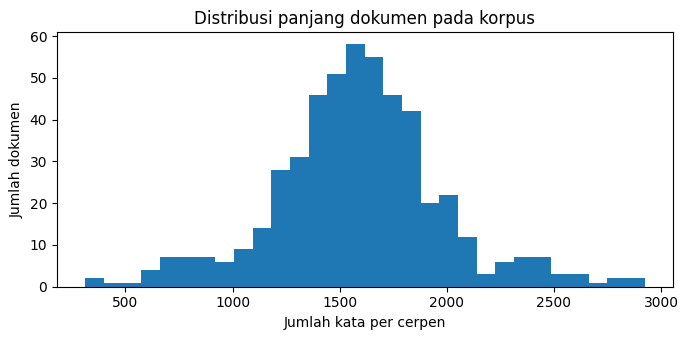

In [12]:
# Statistik panjang dokumen pada korpus akhir
words = pd.Series([r["n_words"] for r in raw])
print(words.describe().round(0).to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(words, bins=30)
ax.set_xlabel("Jumlah kata per cerpen")
ax.set_ylabel("Jumlah dokumen")
ax.set_title("Distribusi panjang dokumen pada korpus")
plt.tight_layout()
plt.show()

## 5. Custom preprocessing

Preprocessing ditulis sebagai satu modul, `preprocess.py`, yang dipakai **identik** saat indexing dan saat memproses query. Modul ditulis ke `WORK_DIR` oleh sel di bawah dan juga diimpor oleh `app.py`.

**Tahapan**

1. **Cleaning khusus cerpen.** Sisa HTML, URL, emoji dan simbol, tanda kutip dan tanda pisah dialog, garis pemisah dekoratif, penanda "bersambung/tamat", label "Cerpen karya", serta sisa teks "baca juga/related/share".
2. **Case folding dan tokenisasi.** Tanda hubung di dalam kata dipertahankan agar kata ulang seperti *ragu-ragu* tetap utuh sebelum di-stem.
3. **Stopword bertingkat.**
   - Daftar bawaan Sastrawi, **dikurangi** `KEEP_TERMS` (ibu, ayah, anak, istri, suami, kota, desa, dst.). Kata-kata ini ada di daftar bawaan padahal merupakan tema inti cerpen, dan terbukti membuat query "ibu menunggu anak pulang" kehilangan kata *ibu*.
   - Kata pengantar dialog (*ujar, katanya, jawabnya, ...*).
   - Kata narasi umum (*lalu, kemudian, sambil, ...*).
   - Kata kerja dan keterangan generik yang document frequency-nya sangat tinggi (*tinggal, dengar, temu, duduk, ...*).
4. **Stemming Sastrawi**, dengan kamus koreksi `STEM_OVERRIDE` untuk kesalahan stem yang ditemukan pada korpus ini (*mengenali*, *gerakan*, *disyahkan*).

Daftar stopword domain tidak ditebak. Kandidatnya diambil dari term dengan document frequency tertinggi, lalu dipilah secara linguistik: kata kerja atau keterangan generik dibuang, sedangkan kata benda tematik (*rumah, anak, hidup, perempuan, ...*) dipertahankan.

In [13]:
PREPROCESS_SRC = r'''
import re, unicodedata
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# ---------- Stopword: bawaan Sastrawi + domain cerpen + hasil analisis DF ----------
BASE_SW = set(StopWordRemoverFactory().get_stop_words())

# kata tema yang TIDAK boleh dibuang walau ada di daftar bawaan
KEEP_TERMS = {"ibu", "bapak", "ayah", "adik", "kakak", "istri", "suami", "anak",
              "saudara", "teman", "sahabat", "kota", "desa", "perang"}

DIALOG_SW = {"ujar", "kata", "katanya", "berkata", "bertanya", "tanya", "tanyanya",
             "jawab", "jawabnya", "menjawab", "ucap", "ucapnya", "seru", "serunya",
             "sahut", "sahutnya", "bisik", "bisiknya", "gumam", "gumamnya", "ujarnya",
             "kataku", "katamu"}

NARASI_SW = {"tiba", "lalu", "kemudian", "sambil", "seraya", "sebuah", "seorang",
             "sesuatu", "akhirnya", "sebelum", "sesudah", "ketika", "waktu", "hari",
             "saat", "pun", "lah", "kah", "nya", "dia", "aku", "kamu", "kami", "kita",
             "mereka", "kau", "puluh", "tengah", "milik"}

# kata kerja/keterangan generik dengan document frequency sangat tinggi
DF_SW = {"tinggal", "dengar", "temu", "duduk", "pikir", "pandang", "diam", "penuh",
         "salah", "bawa", "buka", "cari", "tahun"}

STOP = (BASE_SW - KEEP_TERMS) | DIALOG_SW | NARASI_SW | DF_SW

# koreksi salah stem Sastrawi yang ditemukan pada korpus ini
STEM_OVERRIDE = {"mengenali": "kenal", "dikenali": "kenal", "dikenalinya": "kenal",
                 "gerakan": "gerak", "gerakannya": "gerak",
                 "disyahkan": "sah", "syah": "sah"}

_stemmer = StemmerFactory().create_stemmer()
_cache = {}

def _stem(w):
    if w in STEM_OVERRIDE:
        return STEM_OVERRIDE[w]
    if w not in _cache:
        s = _stemmer.stem(w)
        _cache[w] = s.split("-")[0] if "-" in s else s
    return _cache[w]

def clean_text(t):
    t = unicodedata.normalize("NFKC", t)
    t = re.sub(r"<[^>]+>", " ", t)                                  # sisa HTML
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)                    # URL
    t = re.sub(r"[\U00010000-\U0010ffff\u2600-\u27bf]", " ", t)     # emoji/simbol
    t = re.sub(r"[“”„‟«»\"'‘’`´]", " ", t)                          # tanda kutip dialog
    t = re.sub(r"[–—―‒]", " ", t)                                   # tanda pisah dialog
    t = re.sub(r"(?m)^\s*[\*\-_=~#•·]{2,}\s*$", " ", t)             # garis pemisah dekoratif
    t = re.sub(r"\b(bersambung|tamat)\b", " ", t, flags=re.I)
    t = re.sub(r"\b(cerpen|cerita pendek)\s+(karya|oleh)\b", " ", t, flags=re.I)
    t = re.sub(r"\b(baca juga|related|share this|like this|bagikan)\b.*", " ", t, flags=re.I)
    return t

def tokenize(t):
    # case folding + pertahankan tanda hubung di dalam kata (kata ulang)
    return re.findall(r"[a-z]+(?:-[a-z]+)*", t.lower())

def preprocess(text, title=""):
    toks = tokenize(clean_text(title + " . " + text))
    toks = [w for w in toks if len(w) > 2 and w not in STOP]
    toks = [_stem(w) for w in toks]
    return [w for w in toks if len(w) > 2 and w not in STOP]
'''
Path(f"{WORK_DIR}/preprocess.py").write_text(PREPROCESS_SRC.lstrip("\n"), encoding="utf-8")

import preprocess
importlib.reload(preprocess)
print("Modul preprocess dimuat | jumlah stopword:", len(preprocess.STOP))

Modul preprocess dimuat | jumlah stopword: 837


In [14]:
# Kata tema yang ikut ada di stopword bawaan Sastrawi (alasan adanya KEEP_TERMS)
print(sorted(preprocess.KEEP_TERMS & preprocess.BASE_SW))
print("Query 'ibu menunggu anak pulang' ->", preprocess.preprocess("ibu menunggu anak pulang"))

['bapak', 'ibu']
Query 'ibu menunggu anak pulang' -> ['ibu', 'tunggu', 'anak', 'pulang']


Korpus bersih dibuat dari korpus mentah dan disimpan terpisah (`clean_corpus.json`). Judul ikut diproses bersama isi. Proses ini memakan beberapa menit karena stemming, sehingga hasilnya dimuat dari berkas bila sudah ada.

In [15]:
FORCE_REPROCESS = False

if os.path.exists(CLEAN_CORPUS) and not FORCE_REPROCESS:
    clean = json.load(open(CLEAN_CORPUS, encoding="utf-8"))
    print("Memuat clean_corpus.json yang sudah ada")
else:
    clean = []
    for i, r in enumerate(raw):
        toks = preprocess.preprocess(r["text"], r["title"])
        clean.append({"id": i, "title": r["title"], "source": r["source"], "url": r["url"],
                      "tokens": " ".join(toks), "n_tokens": len(toks)})
        if (i + 1) % 100 == 0:
            print(i + 1, "/", len(raw))
    json.dump(clean, open(CLEAN_CORPUS, "w", encoding="utf-8"), ensure_ascii=False, indent=1)

assert len(clean) == len(raw)
print("Dokumen:", len(clean), "| rata-rata token per dokumen:", round(sum(c["n_tokens"] for c in clean) / len(clean)))

Memuat clean_corpus.json yang sudah ada
Dokumen: 503 | rata-rata token per dokumen: 704


In [16]:
# Dasar pemilihan stopword domain: 40 term dengan document frequency tertinggi setelah preprocessing
df_count = collections.Counter()
for c in clean:
    df_count.update(set(c["tokens"].split()))
print([(w, n) for w, n in df_count.most_common(40)])

[('rumah', 430), ('jalan', 428), ('hidup', 421), ('anak', 421), ('malam', 398), ('tangan', 388), ('hati', 372), ('tubuh', 363), ('suara', 361), ('kepala', 356), ('pulang', 349), ('wajah', 345), ('nama', 339), ('air', 333), ('perempuan', 332), ('pergi', 331), ('senyum', 326), ('henti', 324), ('cerita', 320), ('ibu', 314), ('pagi', 309), ('kenal', 304), ('mati', 303), ('bayang', 302), ('hilang', 300), ('tunggu', 298), ('makan', 297), ('sakit', 296), ('kota', 295), ('terima', 295), ('tahan', 291), ('suka', 289), ('tidur', 284), ('istri', 283), ('harap', 281), ('teman', 280), ('tua', 279), ('turun', 278), ('bicara', 278), ('tatap', 278)]


In [17]:
# Contoh sebelum dan sesudah preprocessing
for r in raw[:3]:
    snip = r["text"][:320].rsplit(" ", 1)[0]
    print("=" * 60, "\nJUDUL  :", r["title"])
    print("SEBELUM:", snip.replace("\n", " "))
    print("SESUDAH:", " ".join(preprocess.preprocess(snip)))

JUDUL  : Seragam
SEBELUM: Lelaki jangkung berwajah terang yang membukakan pintu terlihat takjub begitu mengenali saya. Pastinya dia sama sekali tidak menyangka akan kedatangan saya yang tiba-tiba. Ketika kemudian dengan keramahan yang tidak dibuat-buat dipersilakannya saya untuk masuk, tanpa ragu-ragu saya memilih langsung menuju amben di
SESUDAH: lelaki jangkung wajah terang pintu takjub kenal sangka ramah sila ragu pilih amben
JUDUL  : Dua Wajah Ibu
SEBELUM: Perempuan tua itu mendongakkan wajah begitu mendengar desingan tajam di atas ubun-ubunnya. Di langit petang yang temaram, ia melihat lampu kuning, hijau, dan merah mengerjap-ngerjap pada ujung-ujung sayap pesawat terbang. Deru burung besi itu kian nyaring begitu melewati tempatnya berjongkok. Ia menghentikan gerakan
SESUDAH: perempuan tua dongak wajah desing tajam ubun langit petang temaram lampu kuning hijau merah kerjap ujung sayap pesawat terbang deru burung besi kian nyaring jongkok henti gerak
JUDUL  : Tangan-Tangan Buntung


## 6. Konfigurasi Elasticsearch dan indexing

Elasticsearch 8.11 dijalankan secara lokal di sesi Colab. Ada dua penyesuaian khusus Colab: modul machine learning dimatikan (`xpack.ml.enabled: false`) dan hierarki cgroup dialihkan, karena tanpa itu Elasticsearch 8.x gagal menyala akibat akses ke `cpu.stat` ditolak. Bila sudah ada Elasticsearch yang berjalan di `localhost:9200`, sel penyalaan dilewati.

Server berjalan di dalam sesi, sehingga indeks hilang ketika sesi berakhir. Karena korpus bersih tersimpan di `WORK_DIR`, indeks dapat dibangun ulang dalam hitungan detik.

In [18]:
ES_DIR = "/content/elasticsearch-8.11.0"

def es_up():
    try:
        return requests.get("http://localhost:9200", timeout=3).status_code == 200
    except Exception:
        return False

def start_elasticsearch(max_wait=300):
    global es_proc
    if es_up():
        print("Elasticsearch sudah menyala.")
        return True
    if not os.path.exists(ES_DIR):
        os.system("cd /content && wget -q https://artifacts.elastic.co/downloads/elasticsearch/elasticsearch-8.11.0-linux-x86_64.tar.gz")
        os.system("cd /content && tar -xzf elasticsearch-8.11.0-linux-x86_64.tar.gz")
        os.system(f"chown -R daemon:daemon {ES_DIR}")
    cfg = f"{ES_DIR}/config/elasticsearch.yml"
    txt = open(cfg).read()
    for line in ["xpack.security.enabled: false", "discovery.type: single-node", "xpack.ml.enabled: false"]:
        if line not in txt:
            txt += "\n" + line
    open(cfg, "w").write(txt + "\n")

    subprocess.run("pkill -f elasticsearch", shell=True)
    time.sleep(2)
    os.makedirs("/tmp/es_logs", exist_ok=True)
    logf = open("/tmp/es_logs/es_stdout.log", "w")
    env = {**os.environ, "ES_JAVA_OPTS": "-Xms1g -Xmx1g -Des.cgroups.hierarchy.override=/"}
    es_proc = subprocess.Popen([f"{ES_DIR}/bin/elasticsearch"], stdout=logf, stderr=subprocess.STDOUT,
                               preexec_fn=lambda: os.setuid(1), env=env)
    for i in range(max_wait // 3):
        time.sleep(3)
        if es_proc.poll() is not None:
            print("Proses berhenti dengan kode", es_proc.returncode)
            break
        if es_up():
            print("Elasticsearch siap, versi:", requests.get("http://localhost:9200").json()["version"]["number"])
            return True
        if i % 10 == 9:
            print(f"  ...masih menunggu ({(i + 1) * 3} detik)")
    print("".join(open("/tmp/es_logs/es_stdout.log").readlines()[-40:]))
    return False

In [19]:
assert start_elasticsearch(), "Elasticsearch gagal menyala, lihat log di atas"

  ...masih menunggu (30 detik)
Elasticsearch siap, versi: 8.11.0


Tiga indeks dibuat dengan satu shard agar statistik koleksi (document frequency, panjang rata-rata dokumen) konsisten. Token hasil preprocessing diindeks dengan analyzer `whitespace` supaya Elasticsearch tidak memprosesnya lagi, sehingga istilah indeks sepenuhnya ditentukan oleh pipeline `preprocess.py`. Indeks baseline menerima teks mentah dan memakai `standard` analyzer. Field `content` menyimpan term vector, yang dibutuhkan untuk posting list dan Rocchio.

In [20]:
from elasticsearch import Elasticsearch, helpers

es = Elasticsearch("http://localhost:9200")

BM25_DEF = {"type": "BM25", "k1": 1.2, "b": 0.75}
LMD_DEF  = {"type": "LMDirichlet", "mu": 2000}
INDEX = {"bm25": "cerpen_bm25", "lmd": "cerpen_lmd", "baseline": "cerpen_baseline"}

In [21]:
def make_index(name, sim_def, analyzer):
    if es.indices.exists(index=name):
        es.indices.delete(index=name)
    es.indices.create(index=name, body={
        "settings": {"number_of_shards": 1, "number_of_replicas": 0,
                     "similarity": {"sim": sim_def}},
        "mappings": {"properties": {
            "content": {"type": "text", "analyzer": analyzer, "similarity": "sim", "term_vector": "yes"},
            "title":   {"type": "keyword", "index": False},
            "url":     {"type": "keyword", "index": False},
            "source":  {"type": "keyword", "index": False},
            "snippet": {"type": "keyword", "index": False},
        }},
    })

def actions(index, use_clean):
    for r, c in zip(raw, clean):
        content = c["tokens"] if use_clean else (r["title"] + " . " + r["text"])
        yield {"_index": index, "_id": c["id"], "_source": {
            "content": content, "title": r["title"], "url": r["url"],
            "source": r["source"], "snippet": r["text"][:300].replace("\n", " ")}}

In [22]:
make_index("cerpen_bm25",     BM25_DEF, "whitespace")
make_index("cerpen_lmd",      LMD_DEF,  "whitespace")
make_index("cerpen_baseline", BM25_DEF, "standard")

helpers.bulk(es, actions("cerpen_bm25", True))
helpers.bulk(es, actions("cerpen_lmd", True))
helpers.bulk(es, actions("cerpen_baseline", False))

for ix in INDEX.values():
    es.indices.refresh(index=ix)
    print(ix, "->", es.count(index=ix)["count"], "dokumen")

cerpen_bm25 -> 503 dokumen
cerpen_lmd -> 503 dokumen
cerpen_baseline -> 503 dokumen


## 7. Model retrieval: BM25, LM Dirichlet, dan baseline

### BM25

$$\text{score}(D,Q)=\sum_{t\in Q}\text{IDF}(t)\cdot\frac{f(t,D)\,(k_1+1)}{f(t,D)+k_1\left(1-b+b\,\frac{|D|}{\text{avgdl}}\right)},\qquad \text{IDF}(t)=\ln\!\left(1+\frac{N-n_t+0{,}5}{n_t+0{,}5}\right)$$

Parameter yang dipakai: **k1 = 1,2** dan **b = 0,75**. `k1` mengatur kejenuhan frekuensi term (kenaikan skor makin kecil untuk kemunculan berulang), sedangkan `b` mengatur seberapa kuat skor dinormalisasi terhadap panjang dokumen. Karena panjang cerpen sangat bervariasi, `b` relevan untuk korpus ini.

### LM Dirichlet

$$\text{score}(D,Q)=\sum_{t\in Q\cap D}\left[\ln\!\left(1+\frac{f(t,D)}{\mu\,p(t\mid C)}\right)+\ln\frac{\mu}{|D|+\mu}\right]$$

dengan $p(t\mid C)$ probabilitas term pada seluruh koleksi. Parameter yang dipakai: **μ = 2000** (nilai bawaan Lucene). `μ` adalah pseudo-count smoothing: makin besar, makin kuat estimasi dokumen ditarik ke model koleksi. Implementasi Lucene membatasi skor agar tidak negatif.

### Baseline

BM25 dengan parameter yang sama, tetapi pada teks mentah dan `standard` analyzer bawaan (tanpa stemming dan tanpa stopword bahasa Indonesia). Karena modelnya sama dengan `cerpen_bm25`, selisih hasil keduanya berasal dari preprocessing.

Parameter kedua model tidak dituning pada data uji.

In [23]:
def search(method, query, k=10):
    # custom: query diproses dengan pipeline YANG SAMA dengan saat indexing
    # baseline: query mentah, diproses standard analyzer di sisi indeks
    q = query if method == "baseline" else " ".join(preprocess.preprocess(query))
    if not q.strip():
        return []
    res = es.search(index=INDEX[method], size=k, _source=["title", "url", "source", "snippet"],
                    query={"match": {"content": {"query": q, "operator": "or"}}})
    return [{"id": int(h["_id"]), "score": round(h["_score"], 3), **h["_source"]}
            for h in res["hits"]["hits"]]

Posting list tidak dibaca langsung dari struktur Lucene, tetapi direkonstruksi lewat API Elasticsearch: daftar dokumen yang memuat sebuah term diambil dengan query `term`, lalu frekuensi term (tf) pada tiap dokumen diambil dari term vector.

In [24]:
def posting_list(index, term, show=10):
    hits = es.search(index=index, size=10000, _source=False,
                     query={"term": {"content": term}})["hits"]["hits"]
    ids = [h["_id"] for h in hits]
    postings = []
    if ids:
        tv = es.mtermvectors(index=index, ids=ids[:show], fields=["content"],
                             term_statistics=True, positions=False, offsets=False)
        for d in tv["docs"]:
            t = d["term_vectors"]["content"]["terms"].get(term)
            if t:
                postings.append((int(d["_id"]), t["term_freq"]))
    return {"term": term, "df": len(ids), "postings (sebagian)": postings}

In [25]:
# Perbandingan tiga konfigurasi pada satu query
q = "ibu menunggu anak pulang"
print("Query:", q, "| setelah preprocessing:", preprocess.preprocess(q))
for m in ["bm25", "lmd", "baseline"]:
    print("\n==", m.upper())
    for r in search(m, q, 5):
        print(f'  {r["score"]:>7} | {r["title"][:50]:50} | {r["source"]}')

Query: ibu menunggu anak pulang | setelah preprocessing: ['ibu', 'tunggu', 'anak', 'pulang']

== BM25
    3.182 | Anak-anak Peluru                                   | cerpenkompas
     3.01 | Sebuah Rencana Hujan                               | cerpenkompas
    2.922 | Bocah-bocah Berseragam Biru Laut                   | cerpenkompas
    2.912 | Langit Malam                                       | cerpenkompas
    2.905 | Seekor Anjing Manis                                | cerpenkompas

== LMD
    3.489 | Anak-anak Peluru                                   | cerpenkompas
    2.183 | Ibu Pulang                                         | cerpenkompas
     2.08 | Bunga dari Ibu                                     | cerpenkompas
    1.992 | Air                                                | cerpenkompas
    1.988 | Tersesat Menunggu Dalam Rindu                      | kumpulanfiksi

== BASELINE
    4.086 | Anak-anak Peluru                                   | cerpenkompas
    3.767 | Sebuah

In [26]:
# Posting list dari indeks: (id dokumen, tf)
for t in ["rumah", "nelayan", "kenal"]:
    print(posting_list("cerpen_bm25", t))

{'term': 'rumah', 'df': 430, 'postings (sebagian)': [(275, 43), (243, 36), (453, 45), (420, 55), (466, 15), (5, 23), (269, 22), (429, 30), (408, 30), (262, 35)]}
{'term': 'nelayan', 'df': 17, 'postings (sebagian)': [(364, 3), (310, 7), (376, 2), (302, 5), (270, 4), (209, 3), (393, 3), (152, 10), (252, 7), (274, 2)]}
{'term': 'kenal', 'df': 304, 'postings (sebagian)': [(430, 5), (4, 5), (500, 4), (236, 7), (369, 10), (502, 8), (139, 7), (193, 7), (42, 6), (98, 6)]}


## 8. Query expansion dengan sinonim

Kamus sinonim buatan sendiri berisi **21 pasangan** istilah yang sesuai ranah cerpen: kekeluargaan, kematian, perantauan, konflik, dan religi. Query diperluas dengan sinonim dari kata-kata asli query (sebelum stemming), lalu sinonim diproses dengan pipeline yang sama. Istilah asli diberi bobot 1,0 dan sinonim 0,5, supaya sinonim tidak menenggelamkan istilah yang diketik pengguna.

Hasil expansion ditampilkan sebagai demonstrasi kualitatif (query dan top-3 sebelum/sesudah). Dokumen baru yang muncul karena expansion belum pernah dinilai relevansinya, sehingga expansion tidak dimasukkan ke perhitungan metrik pada bagian 10.

In [27]:
SYN = {
    "ibu": ["bunda", "emak", "mama"], "pulang": ["kembali", "balik"],
    "menunggu": ["menanti", "penantian"], "nelayan": ["pelaut", "pelayar"],
    "badai": ["topan", "prahara", "ombak"], "sahabat": ["kawan", "karib", "teman"],
    "pengkhianatan": ["khianat", "tipu", "dusta"], "kemiskinan": ["kemelaratan", "melarat", "papa"],
    "korupsi": ["suap", "penyelewengan", "penggelapan"], "kematian": ["meninggal", "wafat", "mati"],
    "kesedihan": ["duka", "pilu", "lara"], "merantau": ["berkelana", "mengembara"],
    "rindu": ["kangen", "kerinduan"], "kampung": ["desa", "dusun"],
    "cinta": ["kasih", "sayang", "asmara"], "perang": ["pertempuran", "peperangan"],
    "hantu": ["arwah", "roh", "setan"], "arwah": ["roh", "hantu"],
    "perselingkuhan": ["selingkuh", "serong", "skandal"], "kiai": ["ulama", "ustaz"],
    "surau": ["langgar", "musala"],
}
json.dump(SYN, open(SYN_FILE, "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("Jumlah pasangan sinonim:", len(SYN))

Jumlah pasangan sinonim: 21


In [28]:
def expansion_terms(query):
    words = re.findall(r"[a-zA-Z]+", query.lower())
    extra = [s for w in words for s in SYN.get(w, [])]
    orig = preprocess.preprocess(query)
    ext = [t for t in preprocess.preprocess(" ".join(extra)) if t not in orig]
    return orig, list(dict.fromkeys(ext))

def search_expanded(method, query, k=10, w_exp=0.5):
    orig, ext = expansion_terms(query)
    if not orig:
        return []
    should = [{"match": {"content": {"query": " ".join(orig), "boost": 1.0}}}]
    if ext:
        should.append({"match": {"content": {"query": " ".join(ext), "boost": w_exp}}})
    res = es.search(index=INDEX[method], size=k, _source=["title", "url", "source", "snippet"],
                    query={"bool": {"should": should}})
    return [{"id": int(h["_id"]), "score": round(h["_score"], 3), **h["_source"]}
            for h in res["hits"]["hits"]]

In [29]:
# Query sebelum dan sesudah expansion (6 query)
for q in ["ibu menunggu anak pulang", "nelayan melaut dan badai", "pengkhianatan sahabat",
          "kematian suami dan kesedihan istri", "hantu dan arwah gentayangan", "kiai dan surau di desa"]:
    orig, ext = expansion_terms(q)
    before = [r["title"][:28] for r in search("bm25", q, 3)]
    after  = [r["title"][:28] for r in search_expanded("bm25", q, 3)]
    print(f"\nQUERY   : {q}\n  sebelum: {orig}\n  sesudah: {orig} + {ext}")
    print(f"  top-3 sebelum: {before}\n  top-3 sesudah: {after}")


QUERY   : ibu menunggu anak pulang
  sebelum: ['ibu', 'tunggu', 'anak', 'pulang']
  sesudah: ['ibu', 'tunggu', 'anak', 'pulang'] + ['bunda', 'emak', 'mama']
  top-3 sebelum: ['Anak-anak Peluru', 'Sebuah Rencana Hujan', 'Bocah-bocah Berseragam Biru ']
  top-3 sesudah: ['Cik Giok', 'Siti Menunggu Nasib', 'Janji Kaci']

QUERY   : nelayan melaut dan badai
  sebelum: ['nelayan', 'laut', 'badai']
  sesudah: ['nelayan', 'laut', 'badai'] + ['layar', 'topan', 'prahara', 'ombak']
  top-3 sebelum: ['Tiada Darah di Lamalera', 'Naomi', 'Cakra Punarbhawa']
  top-3 sesudah: ['Cakra Punarbhawa', 'Cinta di Atas Perahu Cadik', 'Tiada Darah di Lamalera']

QUERY   : pengkhianatan sahabat
  sebelum: ['khianat', 'sahabat']
  sesudah: ['khianat', 'sahabat'] + ['tipu', 'dusta', 'kawan', 'karib', 'teman']
  top-3 sebelum: ['Seragam', 'Perempuan yang Keramas Sebel', 'Membakar Api']
  top-3 sesudah: ['Perempuan yang Keramas Sebel', 'Pesan Pendek dari Sahabat La', 'Mata Ibu']

QUERY   : kematian suami dan kesedi

## 9. Relevance feedback dengan algoritma Rocchio

Query baru dibentuk dari vektor query asli dan vektor dokumen yang dinilai pengguna:

$$\vec{q}_{baru}=\alpha\,\vec{q}_0+\frac{\beta}{|D_r|}\sum_{d\in D_r}\vec{d}-\frac{\gamma}{|D_{nr}|}\sum_{d\in D_{nr}}\vec{d}$$

Parameter: **α = 1,0**, **β = 0,75**, **γ = 0,15**. Vektor dokumen adalah TF-IDF, yaitu $(1+\ln \text{tf})\cdot\ln(N/\text{df})$ dengan normalisasi L2, yang dihitung dari **term vector indeks Elasticsearch**. Hanya term berbobot positif yang dikirim kembali ke indeks sebagai query berbobot, maksimal 15 term. Term baru yang muncul di kurang dari 3 dokumen (`min_df = 3`) dibuang agar nama tokoh yang hanya ada di satu atau dua cerpen umpan balik tidak mendominasi query.

Pada demonstrasi, umpan balik diambil dari penilaian relevansi manual terhadap top-10 hasil awal (berkas `judgment_sheet_filled.csv`, dijelaskan pada bagian 10). Demonstrasi ini bersifat kualitatif dan tidak dihitung dalam metrik, karena dokumen umpan balik otomatis muncul kembali di peringkat atas.

In [30]:
N_DOCS = es.count(index="cerpen_bm25")["count"]
_df_cache = {}

def df_of(t):
    if t not in _df_cache:
        _df_cache[t] = es.count(index="cerpen_bm25", query={"term": {"content": t}})["count"]
    return _df_cache[t]

def doc_vectors(ids, index="cerpen_bm25"):
    # vektor TF-IDF ternormalisasi untuk tiap dokumen, dari term vector indeks
    if not ids:
        return []
    tv = es.mtermvectors(index=index, ids=[str(i) for i in ids], fields=["content"],
                         term_statistics=True, positions=False, offsets=False, payloads=False)
    vecs = []
    for d in tv["docs"]:
        terms = d["term_vectors"]["content"]["terms"]
        v = {t: (1 + math.log(s["term_freq"])) * math.log(N_DOCS / s["doc_freq"]) for t, s in terms.items()}
        norm_ = math.sqrt(sum(x * x for x in v.values())) or 1.0
        vecs.append({t: x / norm_ for t, x in v.items()})
    return vecs

In [31]:
def rocchio(query, rel_ids, nonrel_ids, alpha=1.0, beta=0.75, gamma=0.15, n_terms=15, min_df=3):
    q0 = preprocess.preprocess(query)
    uq = set(q0)
    qv = defaultdict(float)
    for t in uq:
        qv[t] += alpha / math.sqrt(len(uq))
    rel, non = doc_vectors(rel_ids), doc_vectors(nonrel_ids)
    for v in rel:
        for t, x in v.items():
            qv[t] += beta * x / len(rel)
    for v in non:
        for t, x in v.items():
            qv[t] -= gamma * x / len(non)
    ranked = sorted(((t, w) for t, w in qv.items() if w > 0), key=lambda x: -x[1])
    top = [(t, w) for t, w in ranked if t in uq or df_of(t) >= min_df][:n_terms]
    return q0, top

def search_rocchio(method, query, rel_ids, nonrel_ids, k=10, **kw):
    q0, top = rocchio(query, rel_ids, nonrel_ids, **kw)
    should = [{"term": {"content": {"value": t, "boost": round(w * 10, 3)}}} for t, w in top]
    res = es.search(index=INDEX[method], size=k, _source=["title", "url", "source"],
                    query={"bool": {"should": should}})
    hasil = [{"id": int(h["_id"]), "score": round(h["_score"], 3), "title": h["_source"]["title"]}
             for h in res["hits"]["hits"]]
    return q0, top, hasil

In [32]:
# Demonstrasi Rocchio pada satu query uji
DEMO_QID = 1

if not os.path.exists(JUDGE_FILLED):
    print("judgment_sheet_filled.csv belum tersedia; demonstrasi memerlukan penilaian relevansi (bagian 10).")
else:
    jj = pd.read_csv(JUDGE_FILLED, sep=None, engine="python", encoding="utf-8-sig")
    jj["relevan_0_1"] = pd.to_numeric(jj["relevan_0_1"], errors="coerce")
    q = jj.loc[jj.q_id == DEMO_QID, "query"].iloc[0]
    rel_map = {r.doc_id: r.relevan_0_1 for r in jj[jj.q_id == DEMO_QID].itertuples()}

    awal = search("bm25", q, 10)
    print("QUERY:", q, "\n\n--- SEBELUM feedback (1 = relevan, 0 = tidak, ? = belum dinilai) ---")
    for r in awal:
        v = rel_map.get(r["id"])
        print(f'  [{"?" if v is None or pd.isna(v) else int(v)}] {r["id"]:>3} | {r["title"][:45]}')

    REL    = [r["id"] for r in awal if rel_map.get(r["id"]) == 1]
    NONREL = [r["id"] for r in awal if rel_map.get(r["id"]) == 0]
    print("\nFeedback -> relevan:", REL, "| tidak relevan:", NONREL)

    q0, top, hasil = search_rocchio("bm25", q, REL, NONREL)
    print("\nQuery awal   :", q0)
    print("Query Rocchio:", [(t, round(w, 3)) for t, w in top])
    print("\n--- SESUDAH feedback ---")
    for r in hasil:
        v = rel_map.get(r["id"])
        tanda = "feedback" if r["id"] in REL + NONREL else ("belum dinilai" if v is None or pd.isna(v) else int(v))
        print(f'  [{tanda}] {r["id"]:>3} | {r["title"][:45]}')

QUERY: ibu menunggu anak pulang 

--- SEBELUM feedback (1 = relevan, 0 = tidak, ? = belum dinilai) ---
  [1] 224 | Anak-anak Peluru
  [0] 126 | Sebuah Rencana Hujan
  [0] 213 | Bocah-bocah Berseragam Biru Laut
  [0] 233 | Langit Malam
  [0] 131 | Seekor Anjing Manis
  [0] 305 | Ketika Mereka Pulang
  [0] 357 | Kereta Senja
  [0] 472 | Siti Menunggu Nasib
  [1] 398 | Jendela Tua
  [0] 366 | Juru Rias dan Seorang Pesolek

Feedback -> relevan: [224, 398] | tidak relevan: [126, 213, 233, 131, 305, 357, 472, 366]

Query awal   : ['ibu', 'tunggu', 'anak', 'pulang']
Query Rocchio: [('ibu', 0.519), ('pulang', 0.511), ('tunggu', 0.511), ('anak', 0.506), ('gadang', 0.078), ('rantau', 0.071), ('almanak', 0.07), ('jagung', 0.062), ('etek', 0.061), ('jahit', 0.059), ('samba', 0.052), ('lengang', 0.051), ('payakumbuh', 0.05), ('peluru', 0.046), ('sholat', 0.044)]

--- SESUDAH feedback ---
  [feedback] 398 | Jendela Tua
  [feedback] 224 | Anak-anak Peluru
  [belum dinilai] 135 | Kaki yang Terhormat
 

## 10. Relevance judgment dan evaluasi sistem

### Query uji dan penilaian

- **12 query uji** bertema, disesuaikan dengan karakter korpus (cerpen koran): keluarga, kematian, perantauan, konflik sosial, religi, dan sebagainya.
- **Relevance judgment manual (0/1) oleh anggota kelompok**, berdasarkan isi dokumen dan bukan skor algoritma. Kriteria: sebuah cerpen relevan bila tema utama ceritanya sesuai dengan query. Cerpen yang kata kuncinya hanya muncul sekilas dinilai tidak relevan.
- **Pooling.** Dokumen yang dinilai adalah gabungan top-10 dari ketiga konfigurasi untuk tiap query. Dokumen disajikan dalam urutan acak tanpa menampilkan metode maupun skor, sehingga penilai tidak terpengaruh peringkat sistem.
- Penilaian yang sama dipakai untuk ketiga konfigurasi.

### Metrik

Untuk setiap query, dengan $K=10$, $R$ jumlah dokumen relevan dalam pool, dan $r_i\in\{0,1\}$ relevansi dokumen pada peringkat $i$:

$$P@10=\frac{\sum_{i=1}^{10} r_i}{10},\qquad \text{Recall}=\frac{\sum_{i=1}^{10} r_i}{R},\qquad F1=\frac{2\cdot P@10\cdot \text{Recall}}{P@10+\text{Recall}},\qquad AP=\frac{1}{R}\sum_{i=1}^{10} P@i\cdot r_i$$

MAP adalah rata-rata AP seluruh query. Dokumen yang tidak ada di pool dianggap tidak relevan. **Recall dihitung terhadap dokumen relevan di dalam pool**, bukan terhadap seluruh 503 dokumen. Query yang tidak memiliki dokumen relevan di pool dilewati.

In [33]:
K = 10
QUERIES = [
    "ibu menunggu anak pulang", "nelayan melaut dan badai", "pengkhianatan sahabat",
    "kemiskinan dan perjuangan hidup di kota", "korupsi pejabat dan kekuasaan",
    "kematian suami dan kesedihan istri", "merantau dan rindu kampung halaman",
    "cinta yang tidak sampai", "perang dan pengungsian", "hantu dan arwah gentayangan",
    "perselingkuhan dalam rumah tangga", "kiai dan surau di desa",
]

Lembar penilaian dibuat dari pool dengan urutan acak (`random.seed(7)`). Sel ini tidak menimpa `judgment_sheet.csv` yang sudah ada, supaya penilaian yang sudah dikerjakan tetap cocok dengan nomor dokumen.

In [34]:
if os.path.exists(JUDGE_BLANK):
    print("judgment_sheet.csv sudah ada, tidak dibuat ulang.")
else:
    random.seed(7)
    judge_rows, pool_info = [], []
    for qi, q in enumerate(QUERIES, 1):
        pool = {}
        for m in ["bm25", "lmd", "baseline"]:
            for rank, r in enumerate(search(m, q, K), 1):
                pool.setdefault(r["id"], []).append((m, rank))
        ids = list(pool)
        random.shuffle(ids)
        for d in ids:
            judge_rows.append({"q_id": qi, "query": q, "doc_id": d, "title": raw[d]["title"],
                               "url": raw[d]["url"], "isi_awal": raw[d]["text"][:700].replace("\n", " "),
                               "relevan_0_1": ""})
            pool_info.append({"q_id": qi, "doc_id": d, "dari": pool[d]})
    pd.DataFrame(judge_rows).to_csv(JUDGE_BLANK, index=False, encoding="utf-8-sig")
    json.dump(pool_info, open(POOL_INFO, "w"), ensure_ascii=False)
    print("Lembar penilaian dibuat:", len(judge_rows), "dokumen")

judgment_sheet.csv sudah ada, tidak dibuat ulang.


In [35]:
# Memuat penilaian relevansi dan memeriksa kelengkapannya
assert os.path.exists(JUDGE_FILLED), "judgment_sheet_filled.csv belum ada di folder kerja"
j = pd.read_csv(JUDGE_FILLED, sep=None, engine="python", encoding="utf-8-sig")
j["relevan_0_1"] = pd.to_numeric(j["relevan_0_1"], errors="coerce")

n_kosong = int(j["relevan_0_1"].isna().sum())
n_aneh = int((~j["relevan_0_1"].dropna().isin([0, 1])).sum())
print("Baris penilaian:", len(j), "| kosong:", n_kosong, "| bukan 0/1:", n_aneh)
if n_kosong:
    print("Peringatan: baris kosong dihitung sebagai tidak relevan (0).")
j["relevan_0_1"] = j["relevan_0_1"].fillna(0).astype(int)

qrels = {(r.q_id, r.doc_id): r.relevan_0_1 for r in j.itertuples()}
total_rel = j.groupby("q_id")["relevan_0_1"].sum().to_dict()
print("Dokumen relevan per query:", total_rel)

Baris penilaian: 193 | kosong: 0 | bukan 0/1: 0
Dokumen relevan per query: {1: 5, 2: 5, 3: 2, 4: 3, 5: 2, 6: 2, 7: 5, 8: 7, 9: 2, 10: 6, 11: 3, 12: 4}


In [36]:
def metrics(method, qi, query):
    ranked = [r["id"] for r in search(method, query, K)]
    rels = [qrels.get((qi, d), 0) for d in ranked]
    R = total_rel.get(qi, 0)
    if R == 0:
        return None
    p = sum(rels) / K
    rec = sum(rels) / R
    f1 = 2 * p * rec / (p + rec) if (p + rec) else 0.0
    hits, ap = 0, 0.0
    for i, rel in enumerate(rels, 1):
        if rel:
            hits += 1
            ap += hits / i
    return {"P@10": p, "Recall": rec, "F1": f1, "AP": ap / R}

In [37]:
rows = []
for method in ["baseline", "bm25", "lmd"]:
    for qi, q in enumerate(QUERIES, 1):
        m = metrics(method, qi, q)
        if m is None:
            print("Query tanpa dokumen relevan di pool (dilewati):", qi, q)
            continue
        rows.append({"metode": method, "q_id": qi, **m})

df_eval = pd.DataFrame(rows)
tabel = (df_eval.groupby("metode")[["P@10", "Recall", "F1", "AP"]].mean().round(3)
         .rename(columns={"AP": "MAP"}).loc[["baseline", "bm25", "lmd"]])
df_eval.to_csv(f"{WORK_DIR}/evaluasi_per_query.csv", index=False)
tabel.to_csv(f"{WORK_DIR}/evaluasi_ringkasan.csv")
tabel

,P@10,Recall,F1,MAP
metode,,,,
baseline,0.250,0.663,0.349,0.330
bm25,0.283,0.717,0.391,0.388
lmd,0.300,0.769,0.415,0.488


## 11. Analisis hasil

Bagian ini membaca hasil evaluasi secara lebih rinci: nilai AP dan P@10 per query, batas atas P@10 yang mungkin dicapai, uji kemaknaan selisih antar konfigurasi, dan peringkat dokumen relevan pada query yang hasilnya tidak sejalan dengan rata-rata.

In [38]:
# AP dan P@10 per query, dengan batas atas P@10 (dibatasi jumlah dokumen relevan)
R_series = pd.Series(total_rel)
ap = df_eval.pivot(index="q_id", columns="metode", values="AP")
p10 = df_eval.pivot(index="q_id", columns="metode", values="P@10")
tab_q = ap.add_prefix("AP_").join(p10.add_prefix("P10_")).round(3)
tab_q["R_relevan"] = R_series
tab_q["P10_maks"] = (R_series.clip(upper=K) / K).round(2)
print(tab_q.to_string())
print("\nRata-rata P@10 maksimum yang mungkin:", round(tab_q["P10_maks"].mean(), 3))

metode  AP_baseline  AP_bm25  AP_lmd  P10_baseline  P10_bm25  P10_lmd  R_relevan  P10_maks
q_id                                                                                      
1             0.240    0.244   0.352           0.2       0.2      0.3          5       0.5
2             0.534    0.232   0.522           0.4       0.3      0.4          5       0.5
3             0.292    0.500   0.500           0.2       0.1      0.1          2       0.2
4             0.407    0.178   0.083           0.2       0.2      0.1          3       0.3
5             0.350    0.100   0.500           0.2       0.1      0.1          2       0.2
6             0.000    0.250   0.243           0.0       0.1      0.2          2       0.2
7             0.167    0.679   0.800           0.3       0.5      0.4          5       0.5
8             0.571    0.571   0.556           0.4       0.6      0.6          7       0.7
9             0.417    0.226   0.450           0.2       0.2      0.2          2       0.2

Dengan 12 query, selisih rata-rata perlu dibaca bersama ukuran ketidakpastiannya. Dua ukuran dipakai pada selisih AP per query: **uji Wilcoxon signed-rank** (berpasangan, tanpa asumsi distribusi normal) dan **interval kepercayaan 95% bootstrap** (5.000 pengambilan ulang) untuk rata-rata selisih.

In [39]:
from scipy.stats import wilcoxon

def banding(a, b, nama):
    d = (ap[a] - ap[b]).dropna()
    menang, kalah, seri = int((d > 0).sum()), int((d < 0).sum()), int((d == 0).sum())
    try:
        p = wilcoxon(d, zero_method="zsplit").pvalue
    except Exception:
        p = float("nan")
    rng = np.random.default_rng(0)
    boot = [rng.choice(d.values, len(d)).mean() for _ in range(5000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"{nama}: selisih MAP {d.mean():+.3f} | menang {menang}, kalah {kalah}, seri {seri} "
          f"| Wilcoxon p={p:.3f} | CI95 bootstrap [{lo:+.3f}, {hi:+.3f}]")

banding("bm25", "baseline", "BM25 vs baseline ")
banding("lmd", "bm25", "LMD  vs BM25     ")
banding("lmd", "baseline", "LMD  vs baseline ")

BM25 vs baseline : selisih MAP +0.057 | menang 7, kalah 5, seri 0 | Wilcoxon p=0.569 | CI95 bootstrap [-0.099, +0.235]
LMD  vs BM25     : selisih MAP +0.100 | menang 6, kalah 4, seri 2 | Wilcoxon p=0.139 | CI95 bootstrap [+0.023, +0.183]
LMD  vs baseline : selisih MAP +0.157 | menang 8, kalah 4, seri 0 | Wilcoxon p=0.077 | CI95 bootstrap [+0.016, +0.313]


Pada query 2, 4, dan 5, BM25 dengan preprocessing custom memperoleh AP yang jauh lebih rendah daripada baseline. Sel berikut menampilkan token query setelah preprocessing dan peringkat dokumen relevan (dalam top-10) pada tiap konfigurasi, untuk melihat apakah penyebabnya ada pada query atau pada dokumen.

In [40]:
def peringkat_relevan(method, qi, query):
    ranked = [r["id"] for r in search(method, query, K)]
    return [i for i, d in enumerate(ranked, 1) if qrels.get((qi, d), 0) == 1]

for qi in [2, 4, 5]:
    q = QUERIES[qi - 1]
    print(f"\nq{qi}: {q}")
    print("  token custom:", preprocess.preprocess(q))
    for m in ["baseline", "bm25", "lmd"]:
        print(f"  peringkat dokumen relevan ({m}):", peringkat_relevan(m, qi, q))


q2: nelayan melaut dan badai
  token custom: ['nelayan', 'laut', 'badai']
  peringkat dokumen relevan (baseline): [1, 4, 5, 7]
  peringkat dokumen relevan (bm25): [2, 7, 8]
  peringkat dokumen relevan (lmd): [1, 3, 6, 9]

q4: kemiskinan dan perjuangan hidup di kota
  token custom: ['miskin', 'juang', 'hidup', 'kota']
  peringkat dokumen relevan (baseline): [1, 9]
  peringkat dokumen relevan (bm25): [3, 10]
  peringkat dokumen relevan (lmd): [4]

q5: korupsi pejabat dan kekuasaan
  token custom: ['korupsi', 'jabat', 'kuasa']
  peringkat dokumen relevan (baseline): [2, 10]
  peringkat dokumen relevan (bm25): [5]
  peringkat dokumen relevan (lmd): [1]


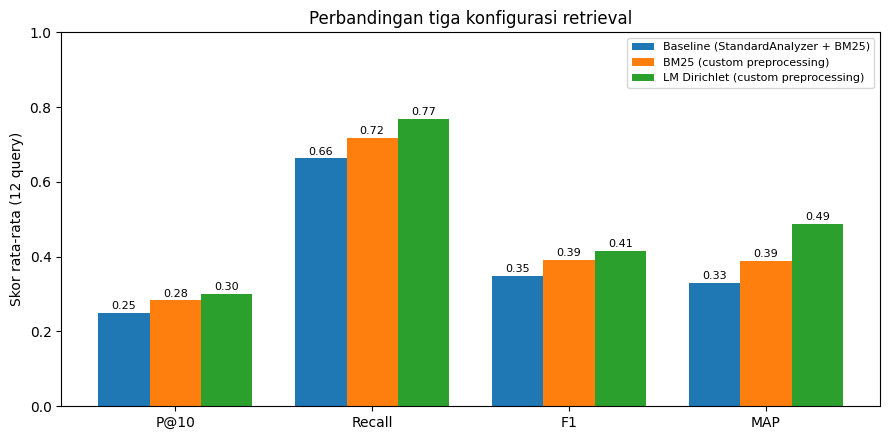

In [41]:
# Grafik 1: rata-rata metrik per konfigurasi
nama = {"baseline": "Baseline (StandardAnalyzer + BM25)", "bm25": "BM25 (custom preprocessing)",
        "lmd": "LM Dirichlet (custom preprocessing)"}
metrik = ["P@10", "Recall", "F1", "MAP"]
x = np.arange(len(metrik))
w = 0.26
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, m in enumerate(["baseline", "bm25", "lmd"]):
    vals = tabel.loc[m, metrik].values
    bars = ax.bar(x + (i - 1) * w, vals, w, label=nama[m])
    for b_, v in zip(bars, vals):
        ax.text(b_.get_x() + b_.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(metrik)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Skor rata-rata (12 query)")
ax.set_title("Perbandingan tiga konfigurasi retrieval")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/evaluasi_grafik.png", dpi=150)
plt.show()

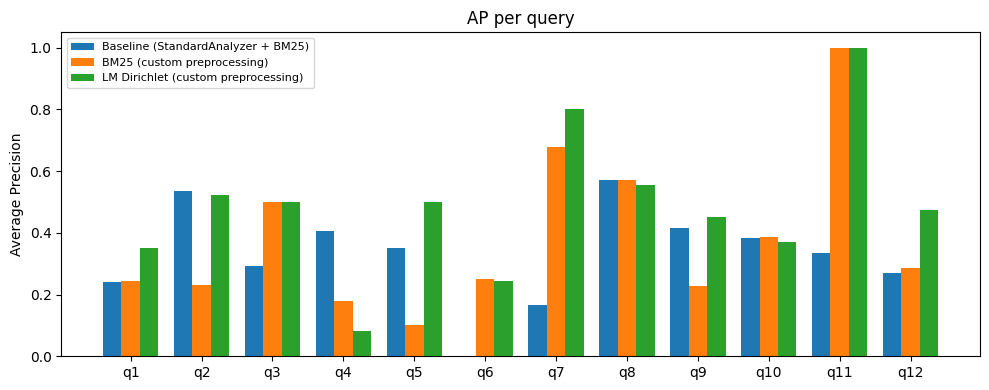

In [42]:
# Grafik 2: AP per query
ap_plot = ap[["baseline", "bm25", "lmd"]]
x = np.arange(len(ap_plot))
fig, ax = plt.subplots(figsize=(10, 4))
for i, m in enumerate(["baseline", "bm25", "lmd"]):
    ax.bar(x + (i - 1) * w, ap_plot[m].values, w, label=nama[m])
ax.set_xticks(x)
ax.set_xticklabels([f"q{q}" for q in ap_plot.index])
ax.set_ylabel("Average Precision")
ax.set_title("AP per query")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{WORK_DIR}/evaluasi_ap_per_query.png", dpi=150)
plt.show()

### Hasil pada eksekusi final

Evaluasi memakai 12 query dan 193 dokumen pool (11 sampai 21 dokumen per query), dengan total 46 dokumen relevan (2 sampai 7 per query).

| Konfigurasi | P@10 | Recall | F1 | MAP |
|---|---|---|---|---|
| Baseline (StandardAnalyzer + BM25) | 0,250 | 0,663 | 0,349 | 0,330 |
| BM25 + custom preprocessing | 0,283 | 0,717 | 0,391 | 0,388 |
| LM Dirichlet + custom preprocessing | 0,300 | 0,769 | 0,415 | 0,488 |

| Perbandingan | Selisih MAP | Menang / kalah / seri (per query) | Wilcoxon p | CI 95% bootstrap |
|---|---|---|---|---|
| BM25 vs baseline | +0,057 | 7 / 5 / 0 | 0,569 | [−0,099; +0,235] |
| LM Dirichlet vs BM25 | +0,100 | 6 / 4 / 2 | 0,139 | [+0,023; +0,183] |
| LM Dirichlet vs baseline | +0,157 | 8 / 4 / 0 | 0,077 | [+0,016; +0,313] |

### Pembahasan

**Urutan konfigurasi.** Pada rata-rata, urutannya konsisten pada keempat metrik: LM Dirichlet, lalu BM25 dengan preprocessing custom, lalu baseline. Selisih paling jelas ada pada MAP, yang berarti dokumen relevan cenderung muncul lebih awal pada peringkat LM Dirichlet.

**Pengaruh preprocessing (BM25 vs baseline).** Rata-rata MAP naik dari 0,330 menjadi 0,388, tetapi kenaikan ini tidak konsisten antar query: BM25 custom lebih baik pada 7 query dan lebih buruk pada 5 query (di antaranya q2, q4, q5, dan q9, dengan selisih AP yang besar), dan uji kemaknaannya tidak menunjukkan perbedaan yang meyakinkan (p = 0,569; interval kepercayaan mencakup nol). Data ini tidak cukup untuk menyimpulkan bahwa preprocessing custom meningkatkan kualitas secara umum. Yang dapat dikatakan: ada kecenderungan kenaikan pada rata-rata, dengan variasi besar antar query. Penjelasan yang masuk akal tetapi belum diuji adalah bahwa stemming menyatukan variasi kata (misalnya *menunggu*, *menanti*, *penantian*) sehingga recall naik, sementara pada query tertentu stemming atau pembuangan stopword menghilangkan atau mengubah kata yang justru membedakan dokumen relevan.

**Perbandingan model (LM Dirichlet vs BM25).** Ini perbedaan yang paling meyakinkan pada data ini: selisih MAP +0,100 dengan interval kepercayaan bootstrap yang tidak mencakup nol, meski uji Wilcoxon (p = 0,139) tidak mencapai tingkat 0,05. LM Dirichlet lebih baik pada 6 query dan lebih buruk pada 4. Salah satu penjelasan yang mungkin adalah panjang cerpen yang sangat bervariasi: smoothing Dirichlet dengan μ = 2000 dapat memperlakukan dokumen panjang berbeda dari normalisasi panjang BM25 (b = 0,75). Penjelasan ini hipotesis, karena parameter kedua model tidak dituning dan pengaruh `b` maupun `μ` tidak diuji.

**Query expansion dan Rocchio.** Expansion mengubah peringkat top-3 pada lima dari enam query demonstrasi dan tidak mengubahnya pada query "kiai dan surau di desa". Pengaruhnya terhadap kualitas tidak diukur karena dokumen baru yang muncul belum dinilai. Pada demonstrasi Rocchio untuk query 1, query bertambah menjadi 15 term dengan bobot β dari dua dokumen relevan. Sebagian term tambahan bersifat tematik (misalnya *rantau*), tetapi banyak yang berupa nama tokoh atau kata khas dua cerpen umpan balik (misalnya *gadang*, *etek*, *payakumbuh*), meskipun sudah disaring dengan `min_df = 3`. Ini gejala umum Rocchio ketika dokumen relevan sangat sedikit. Selain itu, query hasil Rocchio hanya memuat term berbobot positif, sehingga γ hanya menurunkan bobot term yang juga ada di dokumen tidak relevan dan tidak mengeluarkan dokumen tersebut dari hasil (misalnya dokumen 233 yang ditandai tidak relevan tetap muncul).

### Keterbatasan

- **Jumlah query kecil (12) dan dokumen relevan sedikit** (rata-rata sekitar 4 per query dalam pool). P@10 maksimum yang mungkin hanya sekitar 0,38, sehingga nilai P@10 yang rendah mencerminkan batas ini dan bukan semata kualitas sistem. P@10 sebaiknya dibaca bersama MAP.
- **Pooling dibentuk dari sistem yang dibandingkan.** Dokumen relevan yang tidak pernah masuk top-10 ketiga sistem tidak ikut dinilai, sehingga Recall terhadap seluruh korpus tidak diketahui.
- **Satu set penilaian.** Penilaian dikerjakan oleh anggota kelompok tanpa pengukuran kesepakatan antar penilai.
- **Korpus condong ke satu sumber.** Sekitar 91% dokumen berasal dari `cerpenkompas` (cerpen koran bergaya sastra), sehingga query yang dirancang juga bertema sosial dan keluarga. Hasil belum tentu berlaku untuk genre populer seperti cerpen remaja atau horor.
- **Stemmer.** Sastrawi masih menghasilkan sejumlah kesalahan stem (misalnya *pelayar* menjadi *layar*). Sebagian dikoreksi lewat `STEM_OVERRIDE`, tetapi daftar koreksi hanya mencakup kasus yang ditemukan.
- **Parameter tidak dituning.** `k1`, `b`, dan `μ` memakai nilai bawaan atau umum, tanpa penelusuran parameter.
- **Query expansion belum dievaluasi secara kuantitatif.**

## 12. Kesimpulan

1. **Korpus.** Terkumpul 503 cerpen unik dari dua blog WordPress hasil crawling mandiri. Rata-rata panjangnya 1.587 kata per dokumen. Duplicate checking menemukan dua duplikat (satu persis, satu dengan kemiripan 0,9945) yang telah dibuang.
2. **Preprocessing.** Pipeline custom (cleaning cerpen, stopword bertingkat, stemming Sastrawi dengan koreksi) dipakai identik pada indexing dan query. Temuan praktis dari pembangunannya: daftar stopword bawaan Sastrawi membuang kata tema seperti *ibu* sehingga perlu dikecualikan.
3. **Model.** LM Dirichlet menghasilkan MAP tertinggi (0,488), diikuti BM25 dengan preprocessing custom (0,388) dan baseline (0,330). Keunggulan LM Dirichlet atas BM25 adalah perbedaan yang paling meyakinkan secara statistik pada data ini, tetapi masih perlu diuji dengan query dan penilai yang lebih banyak.
4. **Preprocessing custom** menaikkan MAP rata-rata, tetapi tidak konsisten antar query dan belum terbukti bermakna secara statistik. Pada beberapa query baseline justru lebih baik.
5. **Query expansion dan Rocchio** berfungsi dan mengubah query serta peringkat. Rocchio dengan dokumen umpan balik yang sedikit cenderung menambahkan term yang terlalu spesifik pada dokumen tersebut.
6. **Antarmuka.** Mesin pencari dapat dipakai lewat aplikasi Streamlit terpisah (`app.py`), yang memakai tiga indeks Elasticsearch, `preprocess.py`, dan `synonyms.json` yang dihasilkan notebook ini.

Pengembangan lanjutan yang relevan: menambah jumlah query dan penilai (termasuk mengukur kesepakatan antar penilai), menelusuri parameter `k1`, `b`, dan `μ`, memperbaiki penanganan stemming untuk kata khas sastra, memperluas korpus ke genre dan sumber lain, serta mengevaluasi query expansion dengan penilaian untuk dokumen barunya.